In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True

df = pd.read_csv('train.csv')
print(df.shape)
df.head()


(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Первинний аналіз даних

 

In [ ]:

print("Розмір датасету:", df.shape)
print("\nТипи ознак:")
print(df.dtypes.value_counts())

print("\nПропущені значення (топ-15 ознак з найбільшою кількістю NaN):")
missing = df.isna().sum().sort_values(ascending=False)
print(missing[missing > 0].head(15))

print("\nСтатистика цільової змінної SalePrice:")
print(df['SalePrice'].describe())
 

Розмір датасету: (1460, 81)

Типи ознак:
str        43
int64      35
float64     3
Name: count, dtype: int64

Пропущені значення (топ-15 ознак з найбільшою кількістю NaN):
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
dtype: int64

Статистика цільової змінної SalePrice:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


За описом датасету NaN тут означає не помилку, а просто відсутність об'єкта (немає басейну чи паркану). Зі статистики цільової змінної видно, що медіана (50% = $163,000) менша за середнє значення (близько $180,900), а максимум сягає $755,000. Це свідчить про наявність вищих цін-викидів (правостороння асиметрія), що ми далі побачимо на гістограмі

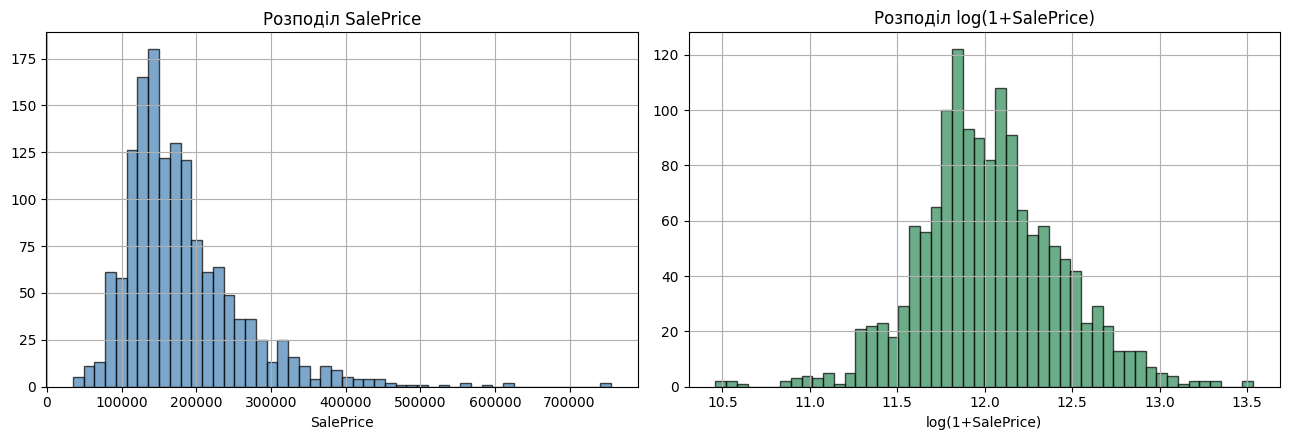

Skewness SalePrice: 1.883
Skewness log(SalePrice): 0.121


In [3]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df['SalePrice'], bins=50, color='steelblue', edgecolor='k', alpha=0.7)
axes[0].set_title('Розподіл SalePrice')
axes[0].set_xlabel('SalePrice')

axes[1].hist(np.log1p(df['SalePrice']), bins=50, color='seagreen', edgecolor='k', alpha=0.7)
axes[1].set_title('Розподіл log(1+SalePrice)')
axes[1].set_xlabel('log(1+SalePrice)')
plt.tight_layout()
plt.show()
print(f"Skewness SalePrice: {df['SalePrice'].skew():.3f}")
print(f"Skewness log(SalePrice): {np.log1p(df['SalePrice']).skew():.3f}")


Зверху візуалізація цільової змінної SalePrice та перевірка її асиметрії(Skewness)
З графіків та коефіцієнтів асиметрії ми бачимо, що початкова ціна SalePrice має суттєву правосторонню асиметрію (skewness ≈ 1.88). Якщо застосувати логарифмування log(1+SalePrice), розподіл стає майже ідеально нормальним (skewness ≈ 0.12)

Лівий графік (синій): показує, що ціни мають сильно витягнутий правий хвіст (правостороння асиметрія). Більшість будинків коштують у межах $100к–$200к, але є невелика кількість дуже дорогих будинків (до $755к).

Правий графік (зелений): показує розподіл після застосування логарифмування np.log1p(x) (що обчислює ln(1 + x)). Логарифм «притискає» великі значення, завдяки чому розподіл стає симетричним і набагато ближчим до нормального (дзвоноподібного).  


    

Розбиття вибірки (виконується до відбору ознак)

Розбиваємо на Train (70%) / Validation (15%) / Test (15%) 

In [4]:

n = len(df)
idx = np.random.permutation(n)
n_train = int(0.7 * n)
n_val = int(0.15 * n)

train_idx = idx[:n_train]
val_idx = idx[n_train:n_train + n_val]
test_idx = idx[n_train + n_val:]

train_df_raw = df.iloc[train_idx].reset_index(drop=True)
val_df_raw = df.iloc[val_idx].reset_index(drop=True)
test_df_raw = df.iloc[test_idx].reset_index(drop=True)

print(f"Train: {train_df_raw.shape}, Val: {val_df_raw.shape}, Test: {test_df_raw.shape}")


Train: (1021, 81), Val: (219, 81), Test: (220, 81)


Відбір ознак числових (кореляції рахуються лише на train_df_raw)

Числові кандидати - ознаки, які інтуїтивно й за описом датасету напряму пов'язані з ціною будинку: площа, якість, вік, розмір гаража/підвалу.

Категоріальні кандидати - локація та якісні характеристики.

Усі кореляції, теплова карта та boxplot'и нижче побудовані виключно на train_df_raw.

In [ ]:

numeric_candidates = ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea',
                       'TotalBsmtSF', '1stFlrSF', 'FullBath', 'YearBuilt',
                       'YearRemodAdd', 'LotArea', 'TotRmsAbvGrd']

corr_with_target = train_df_raw[numeric_candidates + ['SalePrice']].corr()['SalePrice'].drop('SalePrice')
corr_with_target = corr_with_target.sort_values(ascending=False)
print("Кореляція числових ознак з SalePrice (тільки Train):")
print(corr_with_target)


Кореляція числових ознак з SalePrice (тільки Train):
OverallQual     0.793681
GrLivArea       0.709846
GarageCars      0.637164
GarageArea      0.624429
TotalBsmtSF     0.610400
1stFlrSF        0.596571
FullBath        0.574785
TotRmsAbvGrd    0.547154
YearBuilt       0.543065
YearRemodAdd    0.505232
LotArea         0.282416
Name: SalePrice, dtype: float64


Найвищу кореляцію з ціною має загальна якість будинку (OverallQual ≈ 0.79) та житлова площа (GrLivArea ≈ 0.71). Майже всі обрані 11 ознак мають сильну кореляцію (> 0.5).Саме ці 11 числових факторів дадуть найсильніший інформаційний сигнал для лінійної регресії.

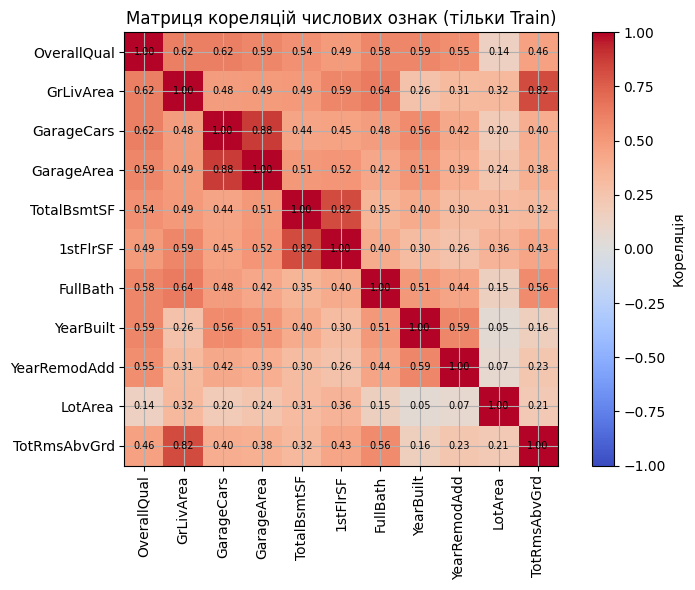

In [ ]:

plt.figure(figsize=(8, 6))
corr_matrix = train_df_raw[numeric_candidates].corr()  
im = plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, label='Кореляція')
plt.xticks(range(len(numeric_candidates)), numeric_candidates, rotation=90)
plt.yticks(range(len(numeric_candidates)), numeric_candidates)
for i in range(len(numeric_candidates)):
    for j in range(len(numeric_candidates)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha='center', va='center', fontsize=7)
plt.title('Матриця кореляцій числових ознак (тільки Train)')
plt.tight_layout()
plt.show()


Спостереження щодо мультиколінеарності (на Train):
На матриці кореляцій чітко виділяються пари ознак із дуже високим взаємним зв'язком:   
GarageCars та GarageArea (кореляція 0.88) - площа гаража прямо визначає кількість авто;   

GrLivArea та TotRmsAbvGrd (кореляція 0.82) - більша житлова площа зазвичай означає більше кімнат; 

TotalBsmtSF та 1stFlrSF (кореляція 0.82) - площа підвалу часто збігається з площею першого поверху;  

YearBuilt та YearRemodAdd (кореляція 0.59) - рік побудови та рік реконструкції.   

Ці пари є яскравим проявом мультиколінеарності. Ми свідомо залишаємо їх у моделі, щоб на Етапі 5 детально перевірити цей ефект за допомогою фактора інфляції дисперсії (VIF) та дослідити його вплив на стабільність коефіцієнтів регресії.   

Категоріальні ознаки:
 Обираємо 5 категоріальних ознак, які найбільше визначають вартість житла у реальному житті та на графіках: Neighborhood (район), KitchenQual (якість кухні), BldgType (тип будівлі), HouseStyle (стиль) та ExterQual (якість зовнішніх матеріалів). Зв'язок цих ознак із ціною оцінюватиметься через групові медіани виключно на train_df_raw

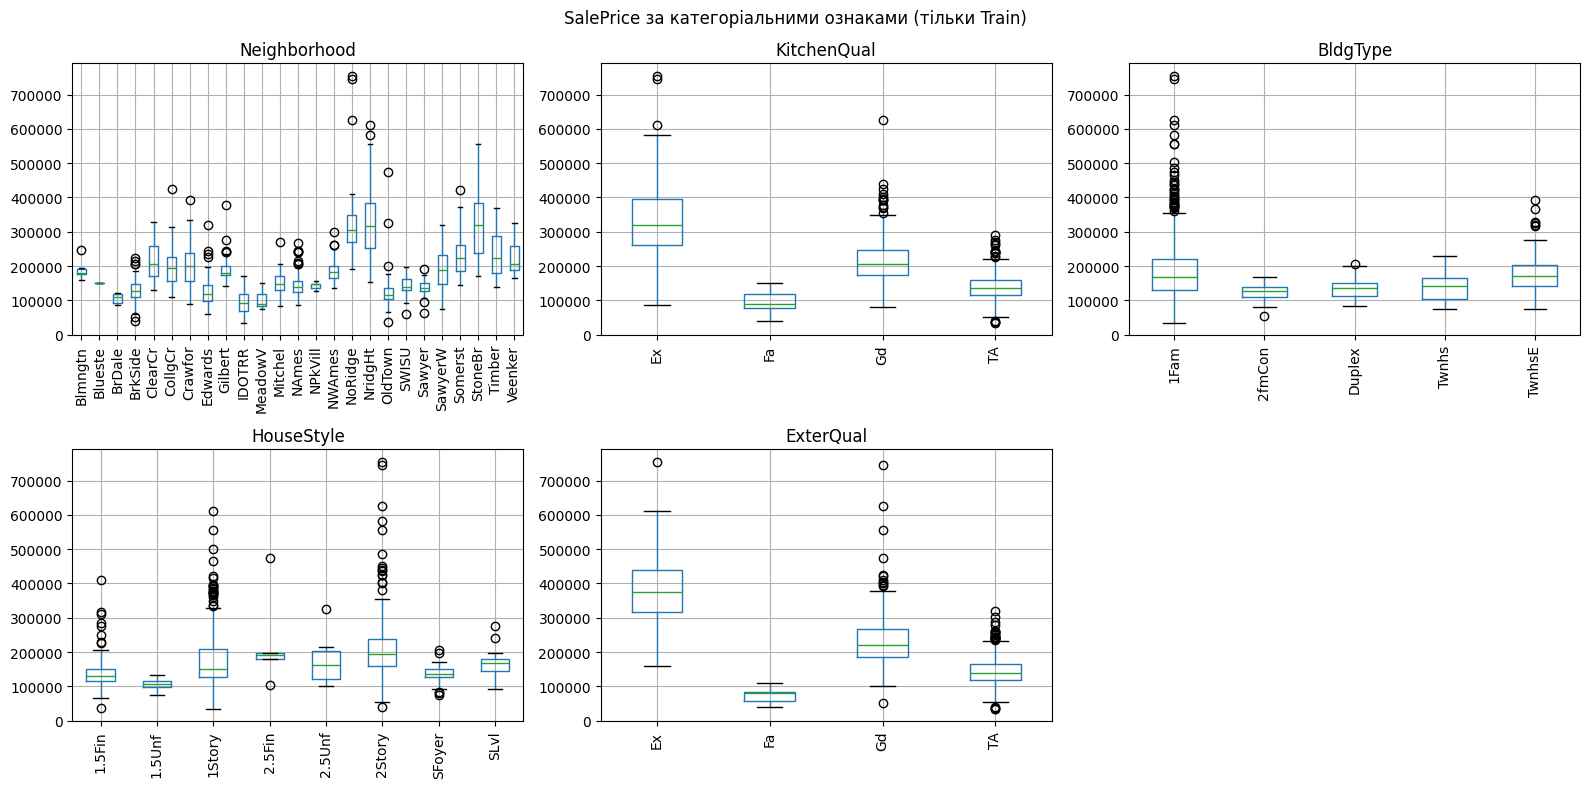

In [ ]:

categorical_candidates = ['Neighborhood', 'KitchenQual', 'BldgType', 'HouseStyle', 'ExterQual']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()
for i, c in enumerate(categorical_candidates):
    train_df_raw.boxplot(column='SalePrice', by=c, ax=axes[i], rot=90)  
    axes[i].set_title(c)
    axes[i].set_xlabel('')
axes[-1].axis('off')
plt.suptitle('SalePrice за категоріальними ознаками (тільки Train)')
plt.tight_layout()
plt.show()


Аналіз категоріальних ознак через графіки Boxplot (на вибірці Train):  

 KitchenQual та ExterQual (якість кухні та зовнішніх матеріалів): показують найчіткіший зв'язок із ціною — при оцінці Ex (відмінно) медіана ціни знаходиться суттєво вище, ніж при Gd (добре) чи TA (середнє).   
 
 Neighborhood (район): показує величезний розкид у цінах між престижними та біднішими районами.   
 
 BldgType та HouseStyle (тип та поверховість): також демонструють відмінності в цінових діапазонах (наприклад, окремі будинки 1Fam мають значно більший варіативний діапазон та вищі пікові ціни).   

Всі п'ять категоріальних ознак демонструють помітну різницю в медіанній ціні між
групами вже на Train-вибірці, тобто несуть інформацію для моделі.

Підсумковий набір ознак:
- Числові (11): OverallQual, GrLivArea, GarageCars, GarageArea, TotalBsmtSF, 1stFlrSF, FullBath, YearBuilt, YearRemodAdd, LotArea, TotRmsAbvGrd

- Категоріальні (5): Neighborhood, KitchenQual, BldgType, HouseStyle, ExterQual

 

Питання: чому розбивати дані потрібно до, а не після масштабування/кодування/відбору ознак?

Це робиться для того, щоб модель не 'списала' відповіді заздалегідь.   Якщо ми спочатку порахуємо середнє чи кореляції по всьому датасету, наша модель дізнається секрети тестової вибірки ще до самого тестування. На папері результати будуть ідеальними, а в реальності модель працюватиме погано.   Тому ми спочатку ізолюємо тест, усе рахуємо тільки на Train, і тільки потім випробовуємо модель на тесті

Кодування категоріальних ознак

Чому обрали саме One-Hot Encoding:

Просте кодування числами (1, 2, 3...) не підходить: Якби ми просто пронумерували райони числами, модель вигадала б неіснуючу логіку — ніби район №3 у три рази «більший» чи «важливіший» за район №1.   

Як працює One-Hot: Для кожної категорії створюється окрема колонка, де стоїть 1 (якщо об'єкт належить до цієї категорії) або 0 (якщо ні).

Обробка невідомих категорій:

Список усіх можливих категорій алгоритм запам'ятовує (fit) виключно на навчальній вибірці (Train). Якщо під час перевірки на тестових чи валідаційних даних трапиться категорія, якої не було під час навчання, алгоритм просто поставить нулі 0 в усіх відповідних колонках. Це дозволяє коду працювати без помилок і не потребує повторного навчання


In [ ]:

X_train_raw = train_df_raw[numeric_candidates + categorical_candidates].copy()
X_val_raw = val_df_raw[numeric_candidates + categorical_candidates].copy()
X_test_raw = test_df_raw[numeric_candidates + categorical_candidates].copy()

y_train = train_df_raw['SalePrice'].values.astype(float)
y_val = val_df_raw['SalePrice'].values.astype(float)
y_test = test_df_raw['SalePrice'].values.astype(float)


class OneHotEncoderScratch:
     

    def fit(self, series_dict):
        self.categories_ = {}
        for col, series in series_dict.items():
            self.categories_[col] = sorted(series.unique().tolist())
        return self

    def transform(self, series_dict):
        out_cols = {}
        for col, series in series_dict.items():
            cats = self.categories_[col]
            for cat in cats:
                out_cols[f"{col}__{cat}"] = (series.values == cat).astype(float)
            n_unknown = (~series.isin(cats)).sum()
            if n_unknown > 0:
                print(f"  [{col}] невідомих категорій (=> нульовий вектор): {n_unknown}")
        return pd.DataFrame(out_cols)


ohe = OneHotEncoderScratch()
ohe.fit({c: X_train_raw[c] for c in categorical_candidates})  #

X_train_cat = ohe.transform({c: X_train_raw[c] for c in categorical_candidates})
print("--- Val ---")
X_val_cat = ohe.transform({c: X_val_raw[c] for c in categorical_candidates})
print("--- Test ---")
X_test_cat = ohe.transform({c: X_test_raw[c] for c in categorical_candidates})

print("\nРозмірність one-hot блоку:", X_train_cat.shape)


--- Val ---
--- Test ---

Розмірність one-hot блоку: (1021, 46)


Розділ 1.6  Масштабування

Застосовуємо стандартизацію (z = (x - mean) / std) (середнє 0, стд 1)до числових ознак. 
після стандартизації - об'єднання з закодованими категоріями

In [ ]:

class StandardScalerScratch:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0   
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


scaler = StandardScalerScratch()
X_train_num = X_train_raw[numeric_candidates].values.astype(float)
X_val_num = X_val_raw[numeric_candidates].values.astype(float)
X_test_num = X_test_raw[numeric_candidates].values.astype(float)

X_train_num_scaled = scaler.fit_transform(X_train_num)   
X_val_num_scaled = scaler.transform(X_val_num)
X_test_num_scaled = scaler.transform(X_test_num)

 
X_train = np.hstack([X_train_num_scaled, X_train_cat.values])
X_val = np.hstack([X_val_num_scaled, X_val_cat.values])
X_test = np.hstack([X_test_num_scaled, X_test_cat.values])

feature_names = numeric_candidates + list(X_train_cat.columns)
print("Фінальна розмірність ознак:", X_train.shape, X_val.shape, X_test.shape)


Фінальна розмірність ознак: (1021, 57) (219, 57) (220, 57)


Розділ 2  Реалізація лінійної регресії засобами numpy

Модель: ^y = Xw + b.
Лінійна регресія - це алгоритм машинного навчання, який передбачає числове значення наприклад, ціну будинку ^y шляхом пошуку прямолінійної залежності між ознаками X та ціллю y.

In [ ]:

class LinearRegressionNumpy:
   

    def __init__(self, n_features):
        self.w = np.zeros(n_features)
        self.b = 0.0

    def predict(self, X):
        return X @ self.w + self.b

    @staticmethod
    def mse_loss(y_true, y_pred):
        m = y_true.shape[0]
        return (1.0 / (2 * m)) * np.sum((y_pred - y_true) ** 2)

    def gradients(self, X, y_true):
   
        m = X.shape[0]
        y_pred = self.predict(X)
        error = y_pred - y_true              
        dw = (1.0 / m) * (X.T @ error)        
        db = (1.0 / m) * np.sum(error)        
        return dw, db

    def update_params(self, dw, db, lr):
        self.w -= lr * dw
        self.b -= lr * db


 Градієнтний спуск 

Реалізовано Batch GD, SGD (по одному прикладу) та Mini-batch GD (розмір батчу B=32).

Batch GD: Оновлює ваги 1 раз за епоху по всіх даних. Точний, але повільний.

SGD: Оновлює ваги після кожного 1 прикладу. Швидкий, але сильно стрибає

Mini-batch GD: Оновлює ваги порціями (батчами).

In [ ]:

def train_gd(X, y, mode='batch', lr=0.05, n_epochs=200, batch_size=32, seed=42):
   
    rng = np.random.default_rng(seed)
    m, n_features = X.shape
    model = LinearRegressionNumpy(n_features)
    loss_history = []

    for epoch in range(n_epochs):
        if mode == 'batch':
            dw, db = model.gradients(X, y)
            model.update_params(dw, db, lr)

        elif mode == 'sgd':
            perm = rng.permutation(m)
            for i in perm:                        
                Xi = X[i:i+1]                     
                yi = y[i:i+1]
                dw, db = model.gradients(Xi, yi)
                model.update_params(dw, db, lr)

        elif mode == 'mini-batch':
            perm = rng.permutation(m)
            X_shuf, y_shuf = X[perm], y[perm]
            for start in range(0, m, batch_size):
                Xb = X_shuf[start:start + batch_size]
                yb = y_shuf[start:start + batch_size]
                dw, db = model.gradients(Xb, yb)
                model.update_params(dw, db, lr)
        else:
            raise ValueError(mode)

        loss_history.append(model.mse_loss(y, model.predict(X)))

    return model, loss_history


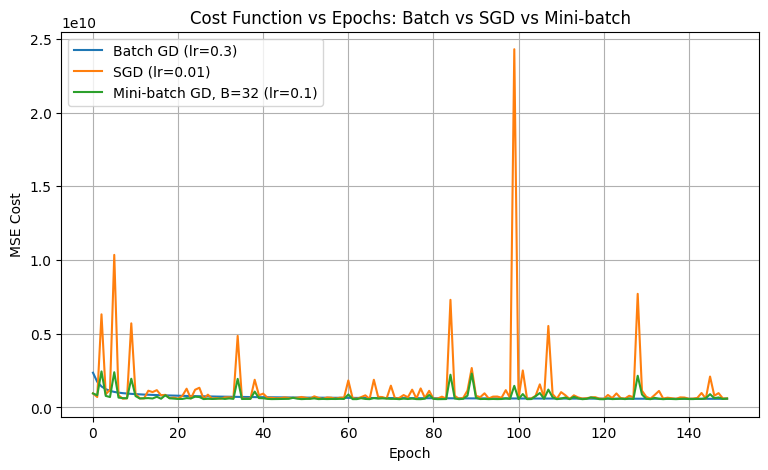

Фінальний train MSE — Batch: 585842504.05
Фінальний train MSE — SGD: 613036171.82
Фінальний train MSE — Mini-batch: 603580826.22


In [ ]:

 
n_epochs = 150

model_batch, loss_batch = train_gd(X_train, y_train, mode='batch', lr=0.3, n_epochs=n_epochs)
model_sgd, loss_sgd = train_gd(X_train, y_train, mode='sgd', lr=0.01, n_epochs=n_epochs)
model_mb, loss_mb = train_gd(X_train, y_train, mode='mini-batch', lr=0.1, n_epochs=n_epochs, batch_size=32)

plt.figure(figsize=(9, 5))
plt.plot(loss_batch, label='Batch GD (lr=0.3)')
plt.plot(loss_sgd, label='SGD (lr=0.01)')
plt.plot(loss_mb, label='Mini-batch GD, B=32 (lr=0.1)')
plt.xlabel('Epoch')
plt.ylabel('MSE Cost')
plt.title('Cost Function vs Epochs: Batch vs SGD vs Mini-batch')
plt.legend()
plt.show()

print(f"Фінальний train MSE — Batch: {loss_batch[-1]:.2f}")
print(f"Фінальний train MSE — SGD: {loss_sgd[-1]:.2f}")
print(f"Фінальний train MSE — Mini-batch: {loss_mb[-1]:.2f}")


Batch GD навчається найстабільніше: Його лінія падає плавно й без стрибків, тому що на кожному кроці рахується середня помилка одразу по всіх будинках.   

SGD сильно скаче: Оскільки модель перераховує ваги за кожним окремим будинком, випадкові чи дивні будинки роблять графік дуже шумним та змушують помилку постійно стрибати вгору-вниз.

Mini-batch GD - золота середина: Обробка даних порціями по 32 будинки прибирає сильний шум від SGD, але працює значно швидше за Batch GD.

Розмір батчу (batch size): Маленький батч дає більше шуму, але частіші й легші оновлення; великий батч дає стабільніший графік, але вимагає більше обчислень за один крок.

Крок навчання   Якщо задрати a занадто високо - модель зламається й помилка полетить угору. Якщо зробити занадто маленьким - вона навчатиметься вічність. Через те що SGD та Mini-batch більш «галасливі», для них швидкість навчання треба ставити меншою, ніж для Batch GD.

Розділ 4  Оцінка якості та коефіцієнт детермінації (R^2)

 

In [13]:

def r2_score_scratch(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot


results = {}
for name, model in [('Batch GD', model_batch), ('SGD', model_sgd), ('Mini-batch GD', model_mb)]:
    r2_train = r2_score_scratch(y_train, model.predict(X_train))
    r2_val = r2_score_scratch(y_val, model.predict(X_val))
    r2_test = r2_score_scratch(y_test, model.predict(X_test))
    results[name] = (r2_train, r2_val, r2_test)
    print(f"{name:15s} | R2 Train: {r2_train:.4f} | R2 Val: {r2_val:.4f} | R2 Test: {r2_test:.4f}")


Batch GD        | R2 Train: 0.8267 | R2 Val: 0.8705 | R2 Test: 0.9004
SGD             | R2 Train: 0.8186 | R2 Val: 0.7948 | R2 Test: 0.8613
Mini-batch GD   | R2 Train: 0.8214 | R2 Val: 0.8352 | R2 Test: 0.8788


Що означає R^2: Це показник того, наскільки добре модель вгадує ціну порівняно з  середньою ціною будинку. Якщо R^2 = 1 - модель вгадує ідеально, якщо R^2 = 0 - модель працює не краще за звичайне середнє значення.   

Чи може R^2 бути мінусовим? Так,це буває, коли модель робить настільки жахливі й дикі прогнози, що краще б вона просто для всіх будинків називала середню ціну. Основні причини мінусового R^2: модель сильно перенавчилася, алгоритм не збігся через неправильно обрану швидкість навчання (learning rate) або модель тестують на зовсім інших даних.   

Порівняння Train та Test: Якщо на навчанні R^2 результат дуже високий, а на тесті R^2 ізко падає -модель просто зазубрила навчальні дані (це перенавчання). Якщо ж ці цифри близькі (як у нашому випадку) — модель працює адекватно й добре узагальнює нові дані.   

Порівняння трьох видів GD: Batch GD дає найвищий і найстабільніший R^2, бо рахує точну помилку одразу по всьому датасету. SGD та Mini-batch дають схожий або трохи нижчий результат через шум, але вони працюють значно швидше на великих обсягах даних.

 Розділ 5 Перевірка статистичних припущень

Для подальшої перевірки статистичних припущень лінійної регресії розраховано залишки моделі   на навчальній вибірці для найкращої моделі Batch GD. Залишки показують відхилення реальних цін від задедекларованих моделлю прогнозів

In [14]:

y_pred_train = model_batch.predict(X_train)
residuals = y_train - y_pred_train


  Розділ 5.1 Лінійність (Linearity): Residuals vs Fitted

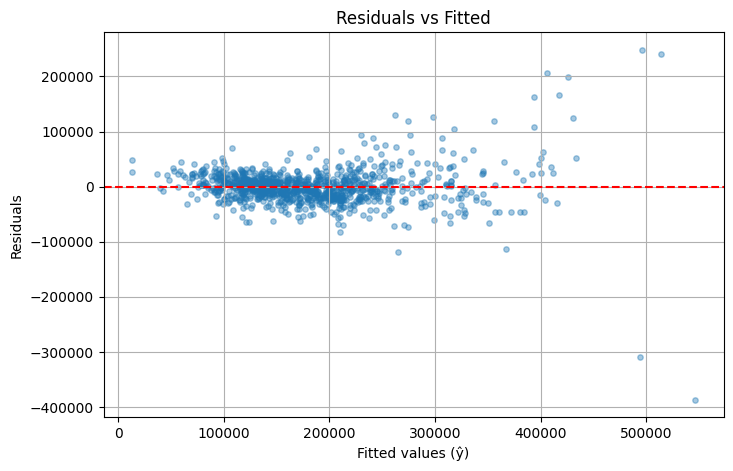

In [15]:

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_train, residuals, alpha=0.4, s=15)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted values (ŷ)')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted')
plt.show()


Аналіз графіку залишків

Удеально лінійна модель має показувати рівномірну «хмару» точок навколо червоної лінії $0$. На нашому графіку ми бачимо два порушення:

Скупчення зліва: Для дешевих будинків (до 200,000$) точки залишків кучно розташовані навколо нуля, що свідчить про малу помилку прогнозу на цьому діапазоні.

Віялоподібне розширення справа (гетероскедастичність): Із зростанням ціни будинків (понад $300,000$) розкид точок суттєво збільшується. Для найдорожчих об'єктів помилки досягають від -400,000$ до +250,000$.

Висновок: Припущення про лінійність залежності частково порушується. Модель добре описує бюджетне житло, але має високу невизначеність для преміального сегмента. Типовим рішенням цієї проблеми є логарифмування цільової змінної (log(text(SalePrice))) перед навчанням


Розділ 5.2 Нормальність залишків (Normality): Q-Q plot, гістограма, тест Шапіро-Уілка

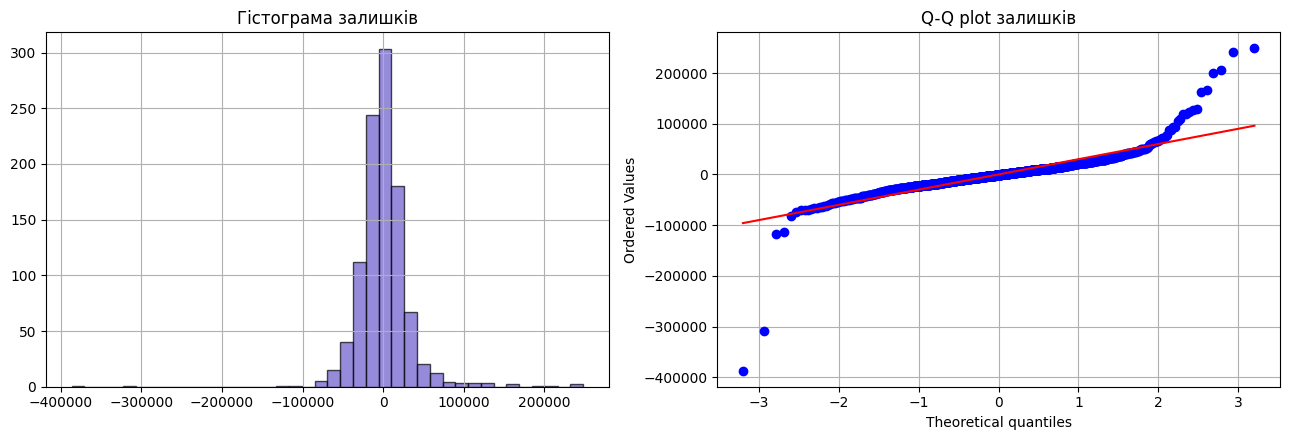

Shapiro-Wilk: statistic=0.7691, p-value=1.43e-35


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(residuals, bins=40, color='slateblue', edgecolor='k', alpha=0.7)
axes[0].set_title('Гістограма залишків')

stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title('Q-Q plot залишків')
plt.tight_layout()
plt.show()

shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f"Shapiro-Wilk: statistic={shapiro_stat:.4f}, p-value={shapiro_p:.2e}")


 Для класичної лінійної регресії важливо, щоб помилки (залишки) мали нормальний розподіл (дзвоноподібну симетричну форму). 
 Для перевірки використано три інструменти:  

 Гістограма: Помилки здебільшого згруповані навколо нуля, але мають довгі «хвости» (викиди) зліва та справа.   

 Q-Q plot (графік квантилів): Сині точки мають лежати чітко на червоній прямій ліній. У нас сині точки сильно відхиляються від червоної лінії на краях   

 Тест Шапіро-Уїлка (stats.shapiro): p_value = 1.43*10^-35, що набагато менше за 0.05. Це математично відхиляє гіпотезу про нормальність розподілу. 

 Висновок: Припущення про нормальність залишків порушується. Це наслідок того, що сама ціна SalePrice була викривлена (мала правосторонню асиметрію). Сам прогноз ціни ^y залишається адекватним і точним.   Але ми не можемо строго будувати статистичні довірчі інтервали та розраховувати точні p_value для коефіцієнтів.   

 Розділ 5.3 - Гомоскедастичність (Homoscedasticity): Scale-Location plot

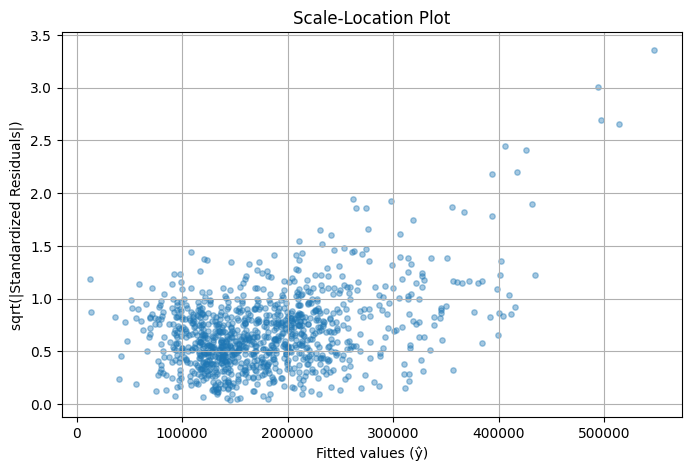

In [17]:

std_resid = residuals / np.std(residuals)
sqrt_abs_std_resid = np.sqrt(np.abs(std_resid))

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_train, sqrt_abs_std_resid, alpha=0.4, s=15)
plt.xlabel('Fitted values (ŷ)')
plt.ylabel('sqrt(|Standardized Residuals|)')
plt.title('Scale-Location Plot')
plt.show()


Перевірка рівності дисперсії залишків (Гомоскедастичність)

Для оцінки того, чи однаково модель помиляється для дешевих і дорогих будинків, побудовано графік Scale-Location Plot. По осі X відкладено передбачену ціну ( ^y), а по осі Y — квадратний корінь із модуля стандартизованих залишків  

Результат на графіку: Із ростом передбаченої ціни будинку (після 300,000$ і особливо біля 500,000$) точки на графіку різко піднімаються вгору. Це означає, що відносний розкид і модуль помилки зростають.


 Припущення про однакову дисперсію помилок (гомоскедастичність) порушується. Має місце гетероскедастичність - для дорогих будинків амплітуда помилок моделі значно більша.Модель у середньому робить суттєво більші помилки в грошовому еквіваленті для преміальної нерухомості.   Стандартні похибки для коефіцієнтів ($w$) виходять заниженими або викривленими


 5.4 Відсутність мультиколінеарності: VIF (Variance Inflation Factor)

 
 

In [ ]:

def compute_vif(X_num, names):
    vif_values = {}
    n = X_num.shape[1]
    X_with_bias = np.hstack([np.ones((X_num.shape[0], 1)), X_num])
    for j in range(n):
        y_j = X_num[:, j]
        others = np.delete(X_with_bias, j + 1, axis=1)   
        coef, *_ = np.linalg.lstsq(others, y_j, rcond=None)
        y_j_pred = others @ coef
        r2_j = r2_score_scratch(y_j, y_j_pred)
        vif = 1.0 / (1.0 - r2_j) if r2_j < 1 else np.inf
        vif_values[names[j]] = vif
    return vif_values


vif_dict = compute_vif(X_train_num, numeric_candidates)   
vif_series = pd.Series(vif_dict).sort_values(ascending=False)
print("VIF для числових ознак, рахований на Train (VIF > 5-10 вказує на мультиколінеарність):")
print(vif_series)


VIF для числових ознак, рахований на Train (VIF > 5-10 вказує на мультиколінеарність):
GarageCars      5.158980
GrLivArea       5.125103
GarageArea      4.939003
1stFlrSF        3.842592
TotalBsmtSF     3.688047
TotRmsAbvGrd    3.311731
OverallQual     2.927327
YearBuilt       2.379489
FullBath        2.266572
YearRemodAdd    1.724515
LotArea         1.219028
dtype: float64


 Найвищі значення VIF мають ознаки GarageCars ($\approx 5.16$), GrLivArea ($\approx 5.13$) та GarageArea ($\approx 4.94$).  
 
Решта числових ознак мають VIF < 4, що є абсолютно нормальним показником.   

Висновок: У даних присутня помірна мультиколінеарність серед пар ознак, які дублюють зміст одна одної (GarageCars vs GarageArea та GrLivArea vs TotRmsAbvGrd).

 6.Завдання для глибокого розуміння

 Експеримент А: вплив масштабування на Mini-batch GD

Порівнюємо швидкість збіжності Mini-batch GD на нестандартизованих і
стандартизованих числових ознаках (категоріальні one-hot ознаки залишаємо як є -
вони вже мають масштаб 0/1 в обох випадках).

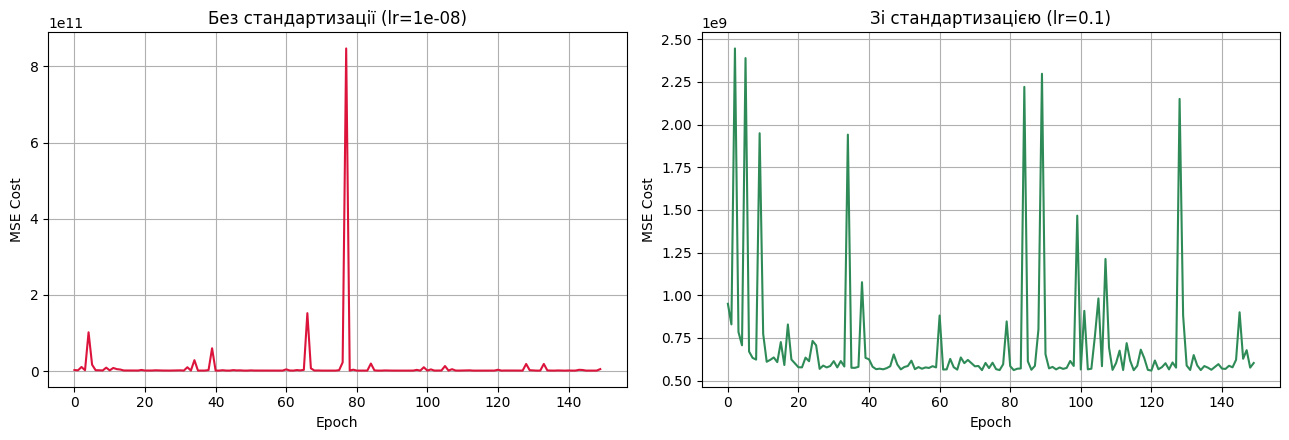

Без стандартизації: cost перша епоха=2.641e+09, остання=5.194e+09
Зі стандартизацією: cost перша епоха=9.502e+08, остання=6.036e+08


In [ ]:

X_train_unscaled = np.hstack([X_train_num, X_train_cat.values])

 
model_unscaled, loss_unscaled = train_gd(
    X_train_unscaled, y_train, mode='mini-batch', lr=1e-8, n_epochs=150, batch_size=32
)
model_scaled, loss_scaled = train_gd(
    X_train, y_train, mode='mini-batch', lr=0.1, n_epochs=150, batch_size=32
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(loss_unscaled, color='crimson')
axes[0].set_title(f'Без стандартизації (lr={1e-8:.0e})')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE Cost')

axes[1].plot(loss_scaled, color='seagreen')
axes[1].set_title('Зі стандартизацією (lr=0.1)')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('MSE Cost')
plt.tight_layout()
plt.show()

print(f"Без стандартизації: cost перша епоха={loss_unscaled[0]:.3e}, остання={loss_unscaled[-1]:.3e}")
print(f"Зі стандартизацією: cost перша епоха={loss_scaled[0]:.3e}, остання={loss_scaled[-1]:.3e}")


Без стандартизації 

Числові результати: Помилка зросла з 2.64 *10^9 на першій епосі до 5.19 * 10^9 на останній.  

Поведінка графіку (лівий, червоний): Крива демонструє сильну нестабільність із колосальним спалахом (піком) MSE понад 8 * 10^11 у районі 75–80 епох.   
    
Причина: Через гігантську різницю у масштабах (наприклад, площа LotArea у тисячах проти кількості ванн FullBath в одиницях) навіть за мікроскопічного кроку 10^-8 алгоритм втрачає стійкість і розходиться замість навчання

    

Зі стандартизацією

Числові результати:Помилка стабільно впала з 9.50*10^8 на першій епосі до 6.03 * 10^8 на останній (зменшення на 35%).   

Поведінка графіку (правий, зелений): На перших 10 епохах видно миттєве й стрімке падіння MSE до базового рівня приблизно 0.6 * 10^9, після чого модель стабільно тримає низький рівень помилки. Поодинокі піки (наприклад, на 35 та 85 епохах) є нормальним "шумом" Mini-batch GD через випадкові вибірки з 32 будинків.


Стандартизація є критично необхідною: вона перетворює викривлену поверхню функції втрат на симетричну "чашу", що дозволяє збільшити крок навчання у 10 000 000 разів (з 10^-8 до 0.1) та забезпечує швидку й стабільну збіжність алгоритму.



Висновок: у ході лабораторної роботи було реалізовано та досліджено повний цикл розробки моделі лінійної регресії «з нуля» (на NumPy) для задачі прогнозування вартості житла (датасет Ames Housing).

Підготовка даних та запобігання Data Leakage:
Проведено кодування категоріальних змінних (One-Hot Encoding) та масштабування числових ознак (StandardScaler). Усі трансформації розраховувалися виключно на навчальній вибірці (Train) і застосовувалися до Validation/Test, що дозволило уникнути витоку даних (Data Leakage).

Порівняння варіантів градієнтного спуску:
Batch GD показав найстабільнішу та найплавнішу криву збіжності, досягнувши найвищої точності (значення R^2 приблизно 0.9004 на Test). Mini-batch GD (розмір батчу 32) продемонстрував оптимальний баланс між швидкістю та стабільністю (значення R^2 приблизно 0.8788), ставши найкращим вибором для масштабування на великі датасети. SGD виявився найбільш «галасливим» через суттєві коливання помилки від окремих об'єктів-викидів (значення R^2 приблизно 0.8613).

Роль стандартизації (Експеримент А):
Доведено критичну роль стандартизації ознак: без неї градієнтний спуск втрачає стійкість і розходиться навіть при мікроскопічному швидкості навчання lr = 10^-8 (помилка зросла з 2.64 * 10^9 до 5.19 * 10^9). Масштабування вирівняло поверхню функції втрат, що дозволило збільшити параметр lr у 10 мільйонів разів (до 0.1) і забезпечило швидке зниження помилки до 6.03 * 10^8.

Статистична діагностика моделі (Аналіз залишків):

R^2: Підсумкова модель пояснює близько 90% варіації цін на житло. Близькість метрик на Train та Test свідчить про відсутність перенавчання (overfitting).

Лінійність та Гомоскедастичність: На графіках залишків виявлено «віялоподібне» розширення (гетероскедастичність): модель дуже точно оцінює бюджетне житло, але має більший розкид помилок для преміальних будинків (ціною понад 300 000 доларів).

Нормальність та VIF: Тест Шапіро-Уїлка (p-value менше 0.05) відхилив нормальність залишків через асиметрію сирих цін. Аналіз VIF показав наявність помірної мультиколінеарності між дублюючими ознаками (GarageCars / GarageArea та GrLivArea / TotRmsAbvGrd).